# Model: comparación y selección

Laboratorio ESPE · Semilla 42 · Fuentes y límites documentados.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / 'data' / 'dataset.csv').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image
df = pd.read_csv(ROOT / 'data/dataset.csv', keep_default_na=False)
df['labels'] = df.labels.map(json.loads)
print('Raíz del laboratorio:', ROOT)


Raíz del laboratorio: D:\ESPE\36902-DESARROLLO SOFTWARE SEGURO\Pacial2\Trabajo


Objetivo: comparar regresión logística One-vs-Rest y Random Forest multisalida. Se prueban C={0.5,2.0} y profundidad={sin límite,18}, con 160 árboles; umbrales 0.30, 0.40, 0.50 y 0.60. Se decide por F1 macro de validación y se prefiere regresión logística en empate. Esta celda realiza el entrenamiento real y serializa el pipeline; puede tardar unos segundos.

In [2]:
from scripts.train import run
experiment = run()
display(pd.read_csv(ROOT / 'output/evaluation/comparison.csv'))
selected = experiment['candidates'][experiment['selected']]
print('Modelo elegido:', selected['algorithm'], 'parámetro:', selected['parameter'], 'umbral:', selected['threshold'])

LogisticRegression parametro=0.5 validacion F1 macro=0.9356


LogisticRegression parametro=2.0 validacion F1 macro=0.9667


RandomForest parametro=None validacion F1 macro=0.9333


RandomForest parametro=18 validacion F1 macro=0.9253


Seleccionado: LogisticRegression; test F1 macro=0.9556; errores=18


,algorithm,parameter,threshold,validation_f1_macro,test_precision_micro,test_recall_micro,test_f1_micro,test_f1_macro
0,LogisticRegression,0.5,0.4,0.935556,0.814815,1.000000,0.897959,0.926667
1,LogisticRegression,2.0,0.4,0.966667,0.880000,1.000000,0.936170,0.955556
2,RandomForest,NaN,0.5,0.933333,0.950820,0.878788,0.913386,0.902924
3,RandomForest,18.0,0.5,0.925333,1.000000,0.878788,0.935484,0.914035


Modelo elegido: LogisticRegression parámetro: 2.0 umbral: 0.4


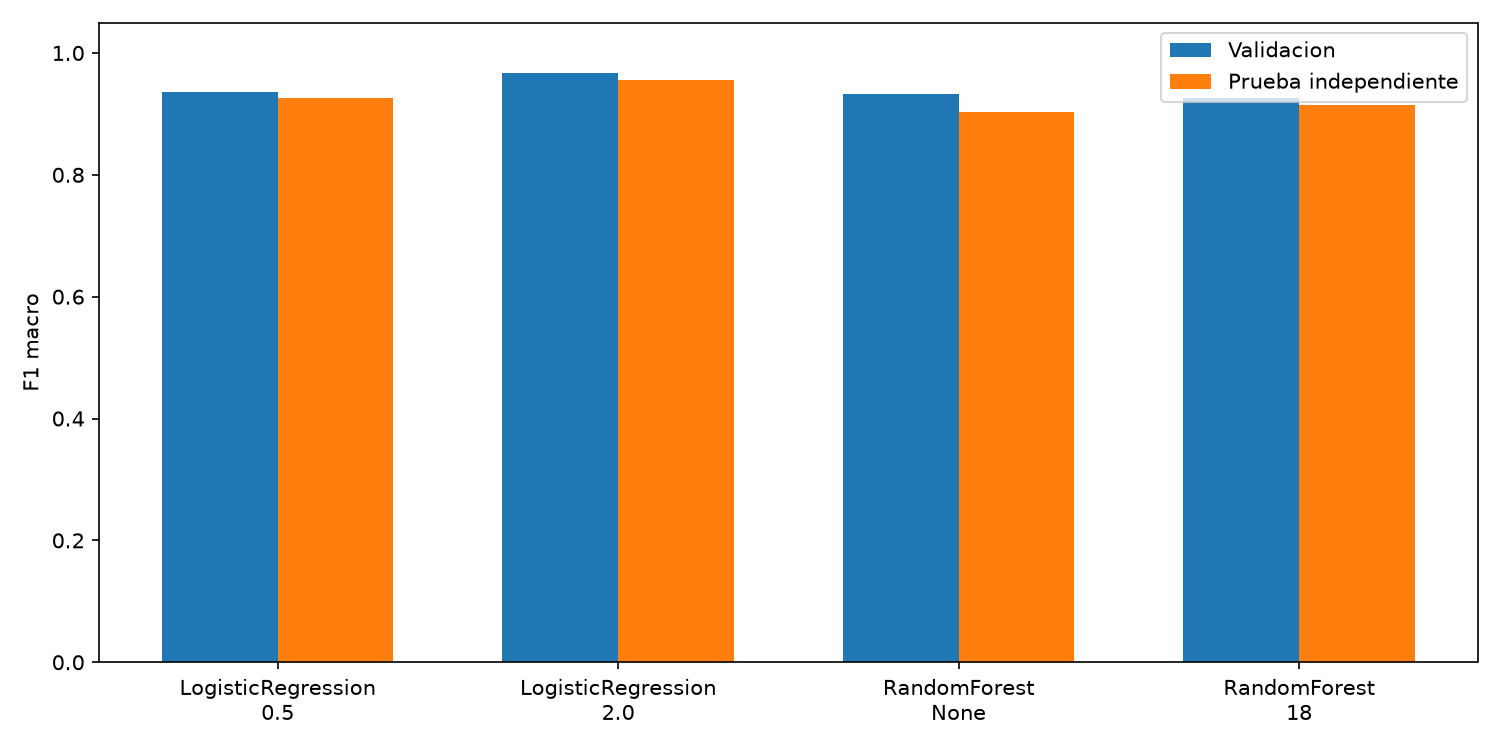

,categoria,puntuacion
0,A01:2025,0.024524
1,A02:2025,0.967666
2,A04:2025,0.016348
3,A05:2025,0.016863
4,A07:2025,0.010515
5,A08:2025,0.024353
6,API10:2023,0.007474
7,API2:2023,0.014410
8,API7:2023,0.024524
9,API8:2023,0.967666


In [3]:
display(Image(filename=str(ROOT / 'output/evaluation/model_comparison.png')))
import joblib
bundle = joblib.load(ROOT / 'vulnminer/artifacts/model.joblib')
example = "app.run(debug=True, port=8099)"
scores = bundle['estimator'].predict_proba(bundle['features'].transform([example]))[0]
display(pd.DataFrame({'categoria':bundle['classes'], 'puntuacion':scores}))

Interpretación: la selección no usa las métricas de prueba. El vocabulario permanece ajustado únicamente con entrenamiento; no se reentrena usando validación para alterar el experimento. Las etiquetas se predicen directamente desde el texto mediante aprendizaje supervisado. Un ejemplo corregido tiene todas las etiquetas a cero. Las puntuaciones no se calibraron como probabilidades de explotación.